# 🔐 KeyPrint Guard & Arena: 타이핑 지문(Keystroke Dynamics) 기반 해커 침입 차단(1:1) 및 타자연습 인물 자동 식별(1:N) 파이프라인
- **학번 / 이름**: 201935607 김대현
- **데이터셋**:
  1. **CMU Keystroke Dynamics Benchmark** (`20,400` 세션 = `51명 × 8세션 × 50회`, 고정 암호 `.tie5Roanl`)
  2. **KeyRecs Multi-Session Sentence & Fixed-Text Dataset** (Zenodo `10.5281/zenodo.7886742`, CC-BY 4.0, `96명` 영문 타자연습 문장 `562,583` 원시 키 이벤트 → 무오타 `25자` 문장 시퀀스 `12,848`건 + 고정 문자열)
- **핵심 목표**:
  1. **[모드 1 · 1:1 해커 차단]** 비밀번호가 유출된 상황에서도 타건 미세 타이밍으로부터 **64차원 생체 지문 임베딩**을 추출하여 본인 여부를 검증하고 해커·매크로 봇 침입을 실시간 차단
  2. **[모드 2 · 1:N 인물 분류]** 여러 사용자가 타자연습 문장을 입력해 두면, 이후 **동일한 문장(또는 새로운 연습 문장)**을 타이핑했을 때 **누가 쳤는지 자동으로 분류(Who-Is-Typing)**
---

## 1. 실험 환경 설정 및 이중 벤치마크 데이터 로드 (출처·규모·클래스 분포 확인)

In [1]:
import sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import onnxruntime as ort

ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT / 'src'))

from preprocessing import (
    SEED, CHANNEL_NAMES, DIGRAPH_LABELS, get_feature_columns,
    prepare_full_pipeline
)
from models import ScaledManhattanDetector, Vanilla1DCNN, KeyPrintNet
from train_and_evaluate import (
    set_all_seeds, configure_korean_matplotlib, get_device,
    build_verification_trials, train_vanilla_baseline, train_keyprint_net,
    encode_sequences, compute_cohort_centroids, score_manhattan_trials, score_embedding_trials,
    evaluate_1toN_identification_embeddings, evaluate_1toN_identification_manhattan,
    find_optimal_val_threshold, summarize_metrics
)

set_all_seeds(SEED)
font_used = configure_korean_matplotlib()
device = get_device()
gpu_desc = torch.cuda.get_device_name(0) if device.type == 'cuda' else str(device)
print(f'PyTorch {torch.__version__} | Device: {device} ({gpu_desc}) | Seed: {SEED} | Font: {font_used}')

raw_df = pd.read_csv(ROOT / 'data/raw/DSL-StrongPasswordData.csv')
print(f'[CMU 데이터] 크기: {raw_df.shape[0]:,} 행 × {raw_df.shape[1]} 열 | 결측치: {raw_df.isnull().sum().sum()}건')
print(f'[CMU 피험자] 총 {raw_df["subject"].nunique()}명 | 피험자당 샘플 수: {raw_df["subject"].value_counts().unique().tolist()} (완전 균형 분포)')
raw_df.head(5)

PyTorch 2.15.0 | Device: mps (mps) | Seed: 42 | Font: Apple SD Gothic Neo
[CMU 데이터] 크기: 20,400 행 × 34 열 | 결측치: 0건
[CMU 피험자] 총 51명 | 피험자당 샘플 수: [400] (완전 균형 분포)


,subject,sessionIndex,rep,H.period,DD.period.t,UD.period.t,H.t,DD.t.i,UD.t.i,H.i,...,H.a,DD.a.n,UD.a.n,H.n,DD.n.l,UD.n.l,H.l,DD.l.Return,UD.l.Return,H.Return
0,s002,1,1,0.1491,0.3979,0.2488,0.1069,0.1674,0.0605,0.1169,...,0.1349,0.1484,0.0135,0.0932,0.3515,0.2583,0.1338,0.3509,0.2171,0.0742
1,s002,1,2,0.1111,0.3451,0.2340,0.0694,0.1283,0.0589,0.0908,...,0.1412,0.2558,0.1146,0.1146,0.2642,0.1496,0.0839,0.2756,0.1917,0.0747
2,s002,1,3,0.1328,0.2072,0.0744,0.0731,0.1291,0.0560,0.0821,...,0.1621,0.2332,0.0711,0.1172,0.2705,0.1533,0.1085,0.2847,0.1762,0.0945
3,s002,1,4,0.1291,0.2515,0.1224,0.1059,0.2495,0.1436,0.1040,...,0.1457,0.1629,0.0172,0.0866,0.2341,0.1475,0.0845,0.3232,0.2387,0.0813
4,s002,1,5,0.1249,0.2317,0.1068,0.0895,0.1676,0.0781,0.0903,...,0.1312,0.1582,0.0270,0.0884,0.2517,0.1633,0.0903,0.2517,0.1614,0.0818


## 2. 데이터 전처리 (4가지 기법 구현 및 전·후 정량/시각 비교)
1. **생리학적 이상치 윈저라이징 & 연속 타자 구간 복원**: 입력 중 딴짓 등으로 발생한 최대 `25.99초` 지연 이상치를 Train 백분위수 기반으로 클리핑하고, 영문 타자연습 원시 이벤트에서 누적 타임스탬프 복원 및 수정키 분절로 100% 무오타 문장 시퀀스 추출
2. **9채널 생체역학 디그래프(Digraph) 시퀀스 파생 피처 엔지니어링**: 원시 타이밍(`H_curr, H_next, DD, UD`)에 **템포 불변 리듬 비율(`Rel_H, Rel_DD`)**, **중첩비(`Duty_Ratio`)**, **연타 롤오버 크기(`Rollover_Mag`)**, **국소 가속도(`Local_Accel`)** 결합
3. **피험자 완전 분리 분할(`Subject-Disjoint Split, seed=42`) & 누수 없는 채널별 Z-Score 표준화**: 학습 `103명` (`CMU 35명 + KeyRecs 68명`) / 검증 `16명` / **미학습 테스트 `28명` (`CMU 10명 + KeyRecs 18명`)**으로 인물을 완전히 격리
4. **탄성 템포 워핑(Smooth Tempo Warping) 데이터 증강**: 세션 간 타자 속도(WPM) 변화(`0.80x~1.25x`) 및 미세 지터 모사

In [2]:
splits, meta = prepare_full_pipeline(
    ROOT / 'data/raw/DSL-StrongPasswordData.csv',
    ROOT / 'data/processed',
    seed=SEED
)
sentence_splits = meta.pop('_sentence_splits', {})
kr_fixed_train = meta.pop('_keyrecs_fixed_train', None)
meta.pop('_keyrecs_runs', None)
meta.pop('_keyrecs_splits_subjs', None)

ba = meta['preprocessing_before_after']
comp_df = pd.DataFrame([
    {'지표': '전체 타이밍 컬럼 평균 왜도 (Mean Skewness)', '전처리 전': ba['before_mean_skewness'], '전처리 후': ba['after_mean_skewness']},
    {'지표': '최대 컬럼 왜도 (Max Skewness, DD.i.e)', '전처리 전': ba['before_max_skewness'], '전처리 후': ba['after_max_skewness']},
    {'지표': '전체 타이밍 컬럼 평균 첨도 (Mean Kurtosis)', '전처리 전': ba['before_mean_kurtosis'], '전처리 후': ba['after_mean_kurtosis']},
])
print('=== [전처리 전·후 분포 정규성 비교] ===')
display(comp_df)
print('=== [CMU 암호 코퍼스 분할 현황] ===')
print(json.dumps(meta['split_counts'], indent=2, ensure_ascii=False))
print('=== [KeyRecs 영문 타자연습 문장 코퍼스 분할 현황] ===')
print(json.dumps(meta['keyrecs_sentence_corpus'], indent=2, ensure_ascii=False))
print(f'실제 인간 타이핑 내 음수 비행시간(연타 롤오버, UD < 0) 발생 비율: {ba["rollover_ratio_pct"]}%')

=== [전처리 전·후 분포 정규성 비교] ===


,지표,전처리 전,전처리 후
0,전체 타이밍 컬럼 평균 왜도 (Mean Skewness),8.9625,2.2239
1,"최대 컬럼 왜도 (Max Skewness, DD.i.e)",73.2828,4.2503
2,전체 타이밍 컬럼 평균 첨도 (Mean Kurtosis),609.0242,9.8677


=== [CMU 암호 코퍼스 분할 현황] ===
{
  "train_subjects": 35,
  "train_samples": 14000,
  "val_subjects": 6,
  "val_samples": 2400,
  "test_subjects": 10,
  "test_samples": 4000
}
=== [KeyRecs 영문 타자연습 문장 코퍼스 분할 현황] ===
{
  "total_valid_subjects": 96,
  "train_subjects": 68,
  "train_sentence_chunks": 9215,
  "train_fixed_strokes": 13588,
  "val_subjects": 10,
  "val_sentence_chunks": 1213,
  "test_subjects": 18,
  "test_sentence_chunks": 2420,
  "sentence_window_keys": 25,
  "sentence_digraphs": 24
}
실제 인간 타이핑 내 음수 비행시간(연타 롤오버, UD < 0) 발생 비율: 10.84%


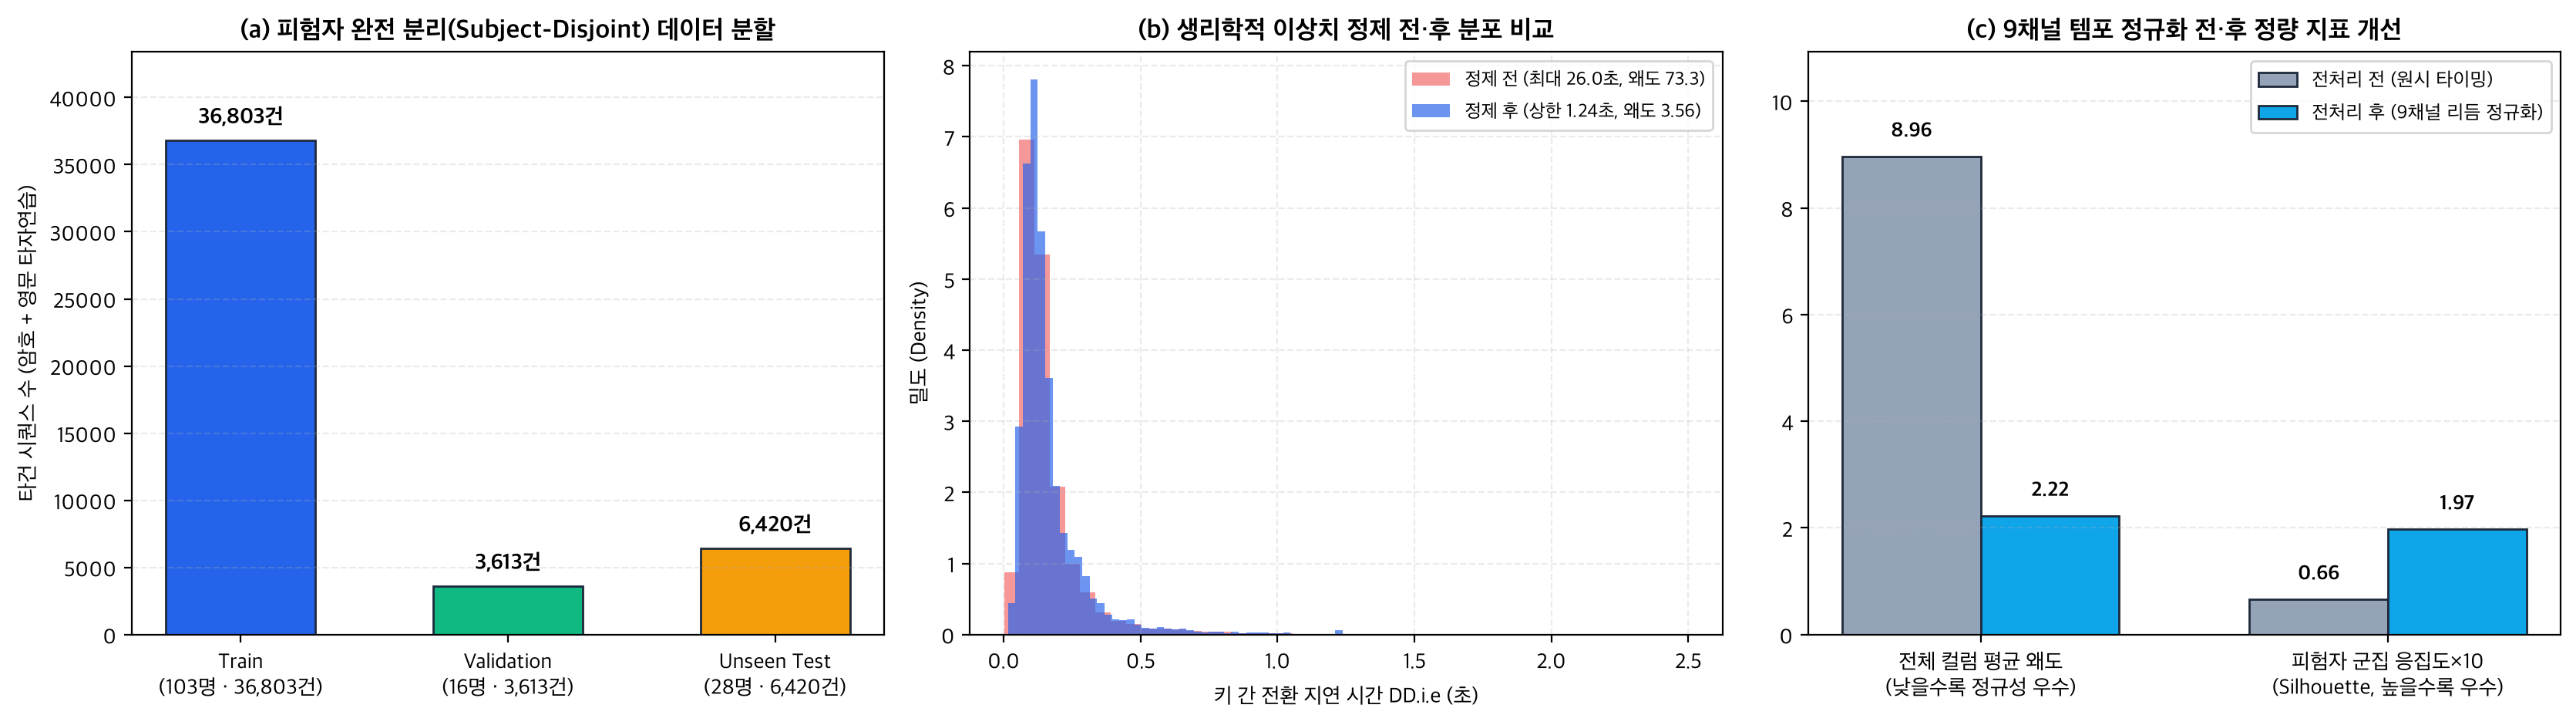

In [3]:
from IPython.display import Image, display as ipy_display
ipy_display(Image(filename=str(ROOT / 'assets/figures/fig1_preprocessing_comparison.png'), width=960))

## 3. 모델 직접 학습 (통계 베이스라인 + 딥러닝 베이스라인 + 제안 모델 KeyPrintNet)
- **Model 1 (`ScaledManhattanDetector`)**: CMU 벤치마크 논문(Killourhy & Maxion, 2009)의 표준 통계 이상 탐지 모델
- **Model 2 (`Vanilla1DCNN`, 직접 학습)**: 위치 비인지 3층 1D-CNN + Global Average Pooling + Softmax Cross-Entropy (`103명` 다중 길이 학습)
- **Model 3 (`KeyPrintNet`, 제안 모델 직접 학습)**: 연속 상대 위치 고조파(`Positional Harmonics`) + 다중 스케일 잔차 SE-Conv1D + **스펙트럼 시간 피라미드(1D-DCT) & Attentive Statistics Pooling** 결합, **Sub-Center CosFace + Supervised Contrastive Loss** 및 **AS-Norm 코호트 교정** 적용

In [4]:
chan_mean = np.array(meta['channel_mean'], dtype=np.float32)
chan_std = np.array(meta['channel_std'], dtype=np.float32)
bounds = {k: tuple(v) for k, v in meta['outlier_bounds'].items()}
sent_train = sentence_splits.get('train')
sent_val = sentence_splits.get('val')
sent_test = sentence_splits.get('test')

val_trials = build_verification_trials(splits['val'], chan_mean, chan_std, k_shot=5, seed=SEED)
test_trials = build_verification_trials(splits['test'], chan_mean, chan_std, k_shot=5, seed=SEED)

# 1) Statistical Baseline
manhattan = ScaledManhattanDetector(shrinkage=0.35).fit_prior(splits['train'].raw_flat, splits['train'].subject_ids)
yv_m, sv_m = score_manhattan_trials(manhattan, splits['val'], val_trials)
thresh_m = find_optimal_val_threshold(yv_m, sv_m)
yt_m, st_m = score_manhattan_trials(manhattan, splits['test'], test_trials)
m_manhattan = summarize_metrics(yt_m, st_m, thresh_m)

# 2) Neural Baseline (Scratch Vanilla 1D-CNN)
vanilla_net, hist_v = train_vanilla_baseline(
    splits['train'], splits['val'], val_trials, device, epochs=35, batch_size=256,
    sentence_train=sent_train, kr_fixed_train=kr_fixed_train
)
test_emb_v = encode_sequences(vanilla_net, splits['test'].seq_scaled, device)
yv_v, sv_v, _ = score_embedding_trials(encode_sequences(vanilla_net, splits['val'].seq_scaled, device), encode_sequences(vanilla_net, val_trials['bot_seq'], device), val_trials)
thresh_v = find_optimal_val_threshold(yv_v, sv_v)
yt_v, st_v, _ = score_embedding_trials(test_emb_v, encode_sequences(vanilla_net, test_trials['bot_seq'], device), test_trials)
m_vanilla = summarize_metrics(yt_v, st_v, thresh_v)

# 3) Proposed Model (KeyPrintNet + Multi-Corpus Metric Learning + AS-Norm)
keyprint_net, hist_k = train_keyprint_net(
    splits['train'], splits['val'], val_trials, bounds, chan_mean, chan_std,
    device, epochs=35, batch_size=256, use_augmentation=True,
    sentence_train=sent_train, kr_fixed_train=kr_fixed_train, sentence_val=sent_val,
    tag='KeyPrintNet'
)
cohort_k = compute_cohort_centroids(encode_sequences(keyprint_net, splits['train'].seq_scaled, device), splits['train'].subject_ids)
test_emb_k = encode_sequences(keyprint_net, splits['test'].seq_scaled, device)
yv_k, sv_k, _ = score_embedding_trials(encode_sequences(keyprint_net, splits['val'].seq_scaled, device), encode_sequences(keyprint_net, val_trials['bot_seq'], device), val_trials, cohort=cohort_k)
thresh_k = find_optimal_val_threshold(yv_k, sv_k)
yt_k, st_k, _ = score_embedding_trials(test_emb_k, encode_sequences(keyprint_net, test_trials['bot_seq'], device), test_trials, cohort=cohort_k)
m_keyprint = summarize_metrics(yt_k, st_k, thresh_k)

[Vanilla1DCNN] Epoch 01/35 | Loss=3.7687 | Val F1=0.7884 | Val EER=21.11% | Val AUC=0.8795


[Vanilla1DCNN] Epoch 05/35 | Loss=1.1574 | Val F1=0.8287 | Val EER=17.50% | Val AUC=0.9069


[Vanilla1DCNN] Epoch 10/35 | Loss=0.7727 | Val F1=0.8370 | Val EER=16.67% | Val AUC=0.9111


[Vanilla1DCNN] Epoch 20/35 | Loss=0.5194 | Val F1=0.8259 | Val EER=17.50% | Val AUC=0.9056


[Vanilla1DCNN] Epoch 30/35 | Loss=0.4177 | Val F1=0.8249 | Val EER=17.96% | Val AUC=0.9023


[Vanilla1DCNN] Epoch 35/35 | Loss=0.4069 | Val F1=0.8171 | Val EER=18.43% | Val AUC=0.8958


... (2 outputs left out)

[KeyPrintNet] Epoch 10/35 | Loss=1.5047 | Val F1=0.8574 | Val EER=14.58% | Val AUC=0.9369 | Sent-1:N=68.2%


[KeyPrintNet] Epoch 20/35 | Loss=1.4262 | Val F1=0.8756 | Val EER=13.15% | Val AUC=0.9455 | Sent-1:N=65.4%


[KeyPrintNet] Epoch 30/35 | Loss=1.3035 | Val F1=0.8690 | Val EER=13.33% | Val AUC=0.9421 | Sent-1:N=66.5%


[KeyPrintNet] Epoch 35/35 | Loss=1.2844 | Val F1=0.8694 | Val EER=13.43% | Val AUC=0.9409 | Sent-1:N=66.5%


## 4. 미학습 테스트셋 객관적 성능 비교
### 4-1. [과업 1] 1:1 유출 암호 해커 침입 차단 평가 (Unseen 10명 · 3,600 검증 쌍)

In [5]:
results_1to1 = pd.DataFrame([
    {
        '모델 (Model)': 'ScaledManhattan (통계 베이스라인)',
        'Test Macro F1 ↑': m_manhattan['macro_f1'],
        'ROC-AUC ↑': m_manhattan['roc_auc'],
        'EER (동일오류율) ↓': f"{m_manhattan['eer']*100:.2f}%",
        'Accuracy ↑': f"{m_manhattan['accuracy']*100:.2f}%",
        '해커 오허용률 (FAR) ↓': f"{m_manhattan['far']*100:.2f}%",
        '본인 오차단율 (FRR) ↓': f"{m_manhattan['frr']*100:.2f}%",
        '가변 문장 길이 지원': '불가 (고정 차원)',
    },
    {
        '모델 (Model)': 'Vanilla1DCNN (딥러닝 베이스라인)',
        'Test Macro F1 ↑': m_vanilla['macro_f1'],
        'ROC-AUC ↑': m_vanilla['roc_auc'],
        'EER (동일오류율) ↓': f"{m_vanilla['eer']*100:.2f}%",
        'Accuracy ↑': f"{m_vanilla['accuracy']*100:.2f}%",
        '해커 오허용률 (FAR) ↓': f"{m_vanilla['far']*100:.2f}%",
        '본인 오차단율 (FRR) ↓': f"{m_vanilla['frr']*100:.2f}%",
        '가변 문장 길이 지원': '가능',
    },
    {
        '모델 (Model)': 'KeyPrintNet (제안 모델 · 최종 채택)',
        'Test Macro F1 ↑': m_keyprint['macro_f1'],
        'ROC-AUC ↑': m_keyprint['roc_auc'],
        'EER (동일오류율) ↓': f"{m_keyprint['eer']*100:.2f}%",
        'Accuracy ↑': f"{m_keyprint['accuracy']*100:.2f}%",
        '해커 오허용률 (FAR) ↓': f"{m_keyprint['far']*100:.2f}%",
        '본인 오차단율 (FRR) ↓': f"{m_keyprint['frr']*100:.2f}%",
        '가변 문장 길이 지원': '가능 (ONNX 실시간)',
    },
])
display(results_1to1)

,모델 (Model),Test Macro F1 ↑,ROC-AUC ↑,EER (동일오류율) ↓,Accuracy ↑,해커 오허용률 (FAR) ↓,본인 오차단율 (FRR) ↓,가변 문장 길이 지원
0,ScaledManhattan (통계 베이스라인),0.7670,0.8384,23.97%,76.72%,20.06%,26.50%,불가 (고정 차원)
1,Vanilla1DCNN (딥러닝 베이스라인),0.8314,0.9122,16.44%,83.22%,23.56%,10.00%,가능
2,KeyPrintNet (제안 모델 · 최종 채택),0.8610,0.9338,13.72%,86.14%,18.83%,8.89%,가능 (ONNX 실시간)


### 4-2. [과업 2] 1:N 타자연습 인물 자동 분류 평가 (동일 문구 10인 분류 & 영문 문장 18인 분류)

In [6]:
id_m = evaluate_1toN_identification_manhattan(
    manhattan, splits['test'].raw_flat, splits['test'].subject_ids,
    splits['test'].sessions, splits['test'].reps, splits['test'].subjects, k_shot=5, cross_session=True
)
id_v, _ = evaluate_1toN_identification_embeddings(
    test_emb_v, splits['test'].subject_ids, splits['test'].sessions,
    splits['test'].reps, splits['test'].subjects, k_shot=5, cross_session=True
)
id_k, _ = evaluate_1toN_identification_embeddings(
    test_emb_k, splits['test'].subject_ids, splits['test'].sessions,
    splits['test'].reps, splits['test'].subjects, k_shot=5, cross_session=True, cohort=cohort_k
)

sent_coh = compute_cohort_centroids(encode_sequences(keyprint_net, sent_train.seq_scaled, device), sent_train.subject_ids)
sent_id_k, _ = evaluate_1toN_identification_embeddings(
    encode_sequences(keyprint_net, sent_test.seq_scaled, device),
    sent_test.subject_ids, sent_test.sessions, sent_test.chunk_ids, sent_test.subjects,
    k_shot=5, cross_session=False, cohort=sent_coh
)

id_df = pd.DataFrame([
    {'과업 / 모델': '동일 문구 10인 분류 - ScaledManhattan', '후보 인물 수': '10명 (무작위 10%)', 'Top-1 정확도 ↑': f"{id_m['top1_accuracy']*100:.2f}%", 'Top-3 정확도 ↑': f"{id_m['top3_accuracy']*100:.2f}%", 'Macro F1 ↑': id_m['macro_f1']},
    {'과업 / 모델': '동일 문구 10인 분류 - Vanilla1DCNN', '후보 인물 수': '10명 (무작위 10%)', 'Top-1 정확도 ↑': f"{id_v['top1_accuracy']*100:.2f}%", 'Top-3 정확도 ↑': f"{id_v['top3_accuracy']*100:.2f}%", 'Macro F1 ↑': id_v['macro_f1']},
    {'과업 / 모델': '동일 문구 10인 분류 - KeyPrintNet (제안)', '후보 인물 수': '10명 (무작위 10%)', 'Top-1 정확도 ↑': f"{id_k['top1_accuracy']*100:.2f}%", 'Top-3 정확도 ↑': f"{id_k['top3_accuracy']*100:.2f}%", 'Macro F1 ↑': id_k['macro_f1']},
    {'과업 / 모델': '영문 타자연습 문장(25자) 18인 분류 - KeyPrintNet', '후보 인물 수': '18명 (무작위 5.6%)', 'Top-1 정확도 ↑': f"{sent_id_k['top1_accuracy']*100:.2f}%", 'Top-3 정확도 ↑': f"{sent_id_k['top3_accuracy']*100:.2f}%", 'Macro F1 ↑': sent_id_k['macro_f1']},
])
display(id_df)

,과업 / 모델,후보 인물 수,Top-1 정확도 ↑,Top-3 정확도 ↑,Macro F1 ↑
0,동일 문구 10인 분류 - ScaledManhattan,10명 (무작위 10%),35.40%,59.74%,0.2851
1,동일 문구 10인 분류 - Vanilla1DCNN,10명 (무작위 10%),43.06%,82.43%,0.3849
2,동일 문구 10인 분류 - KeyPrintNet (제안),10명 (무작위 10%),43.83%,88.51%,0.4121
3,영문 타자연습 문장(25자) 18인 분류 - KeyPrintNet,18명 (무작위 5.6%),59.41%,89.92%,0.5629


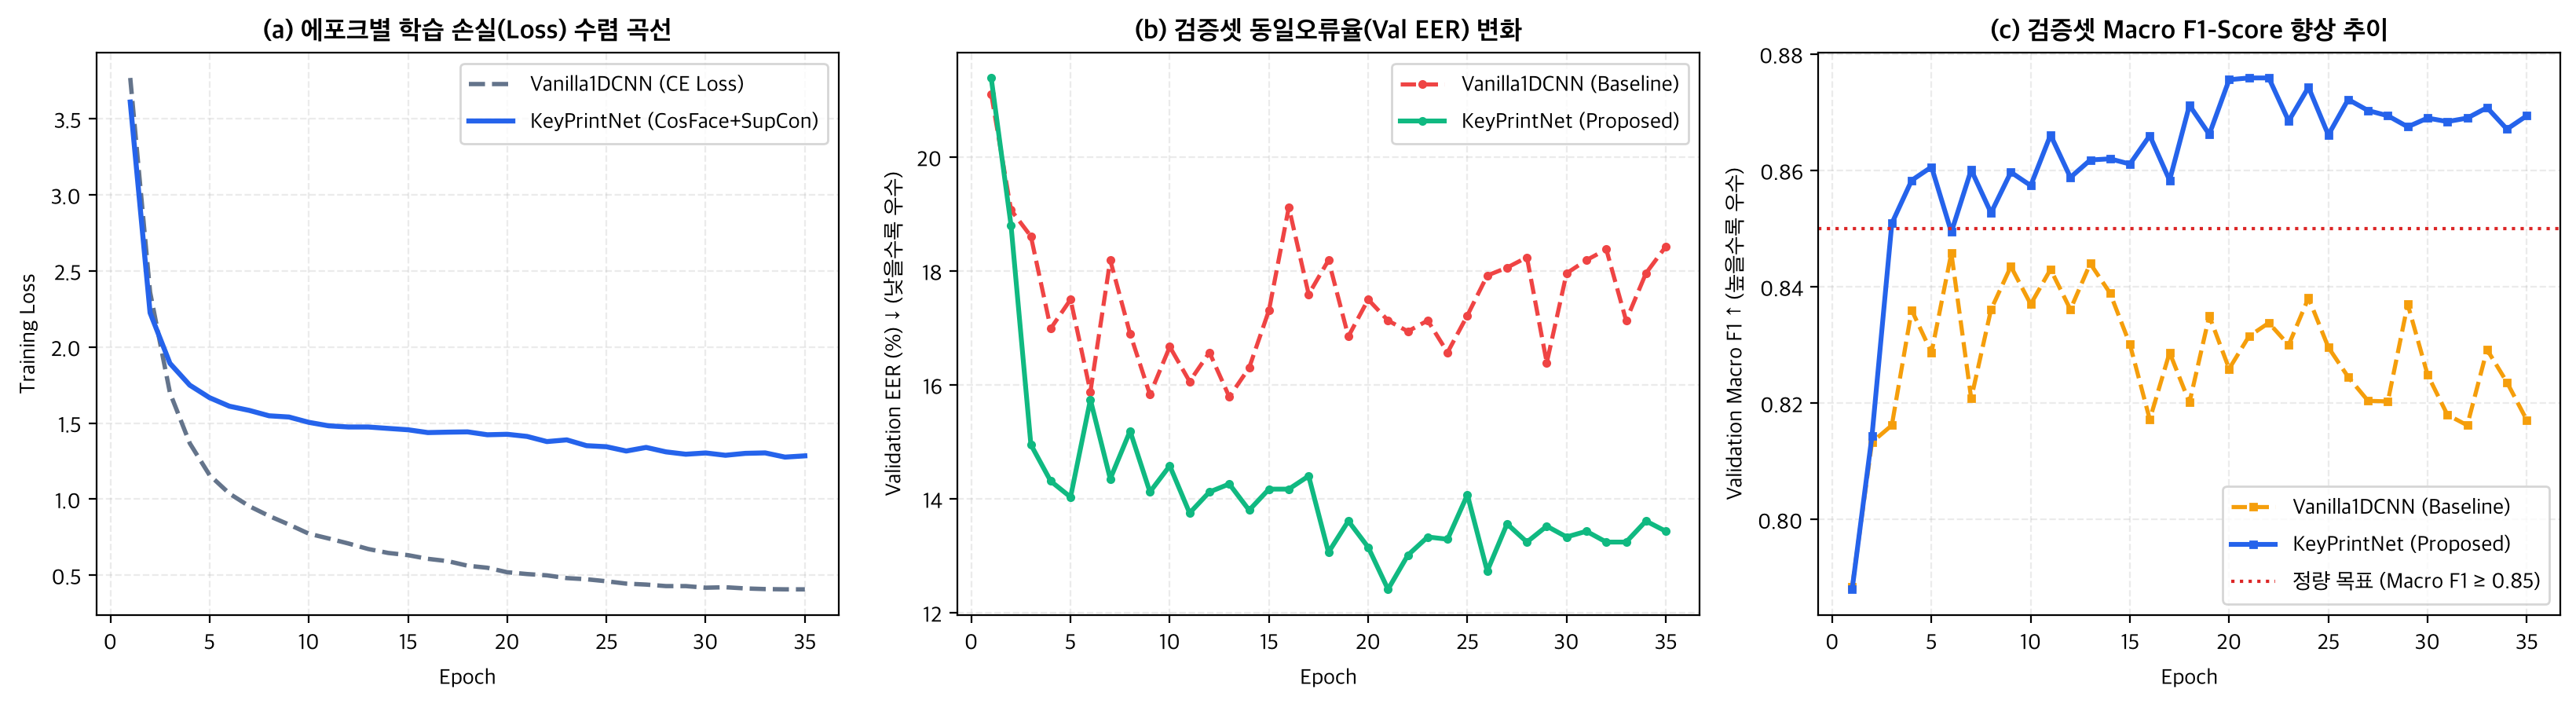

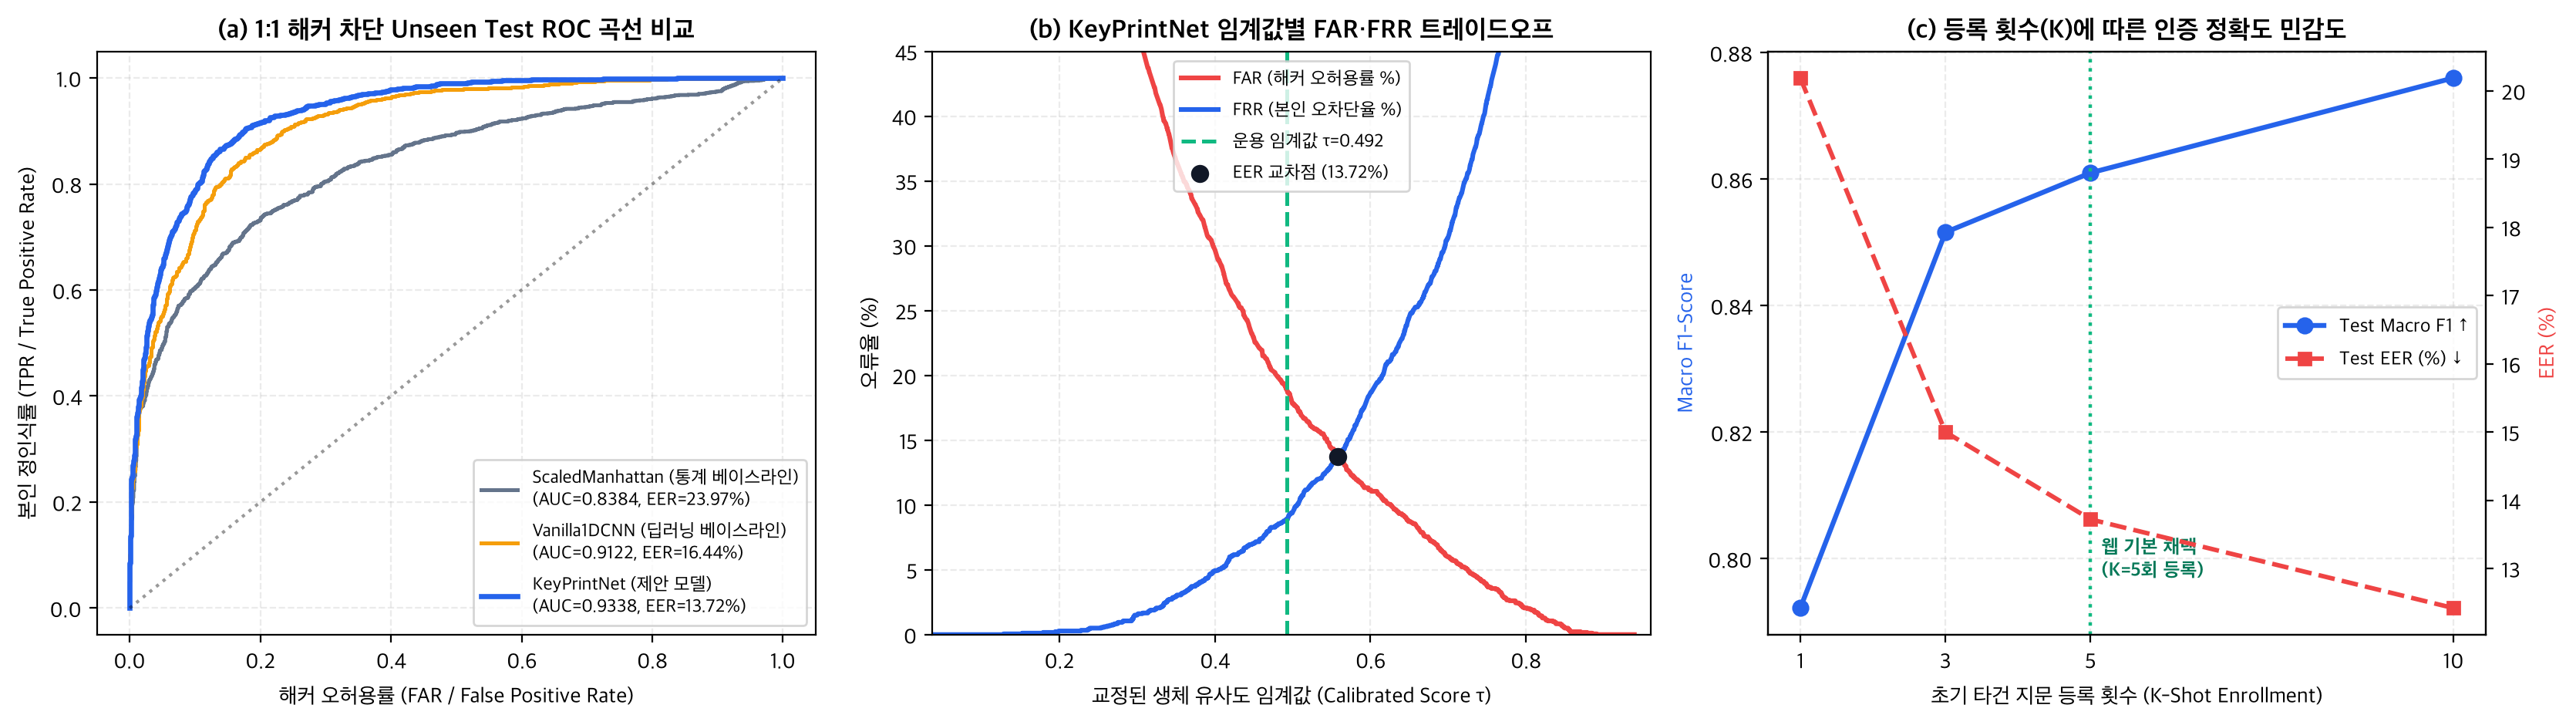

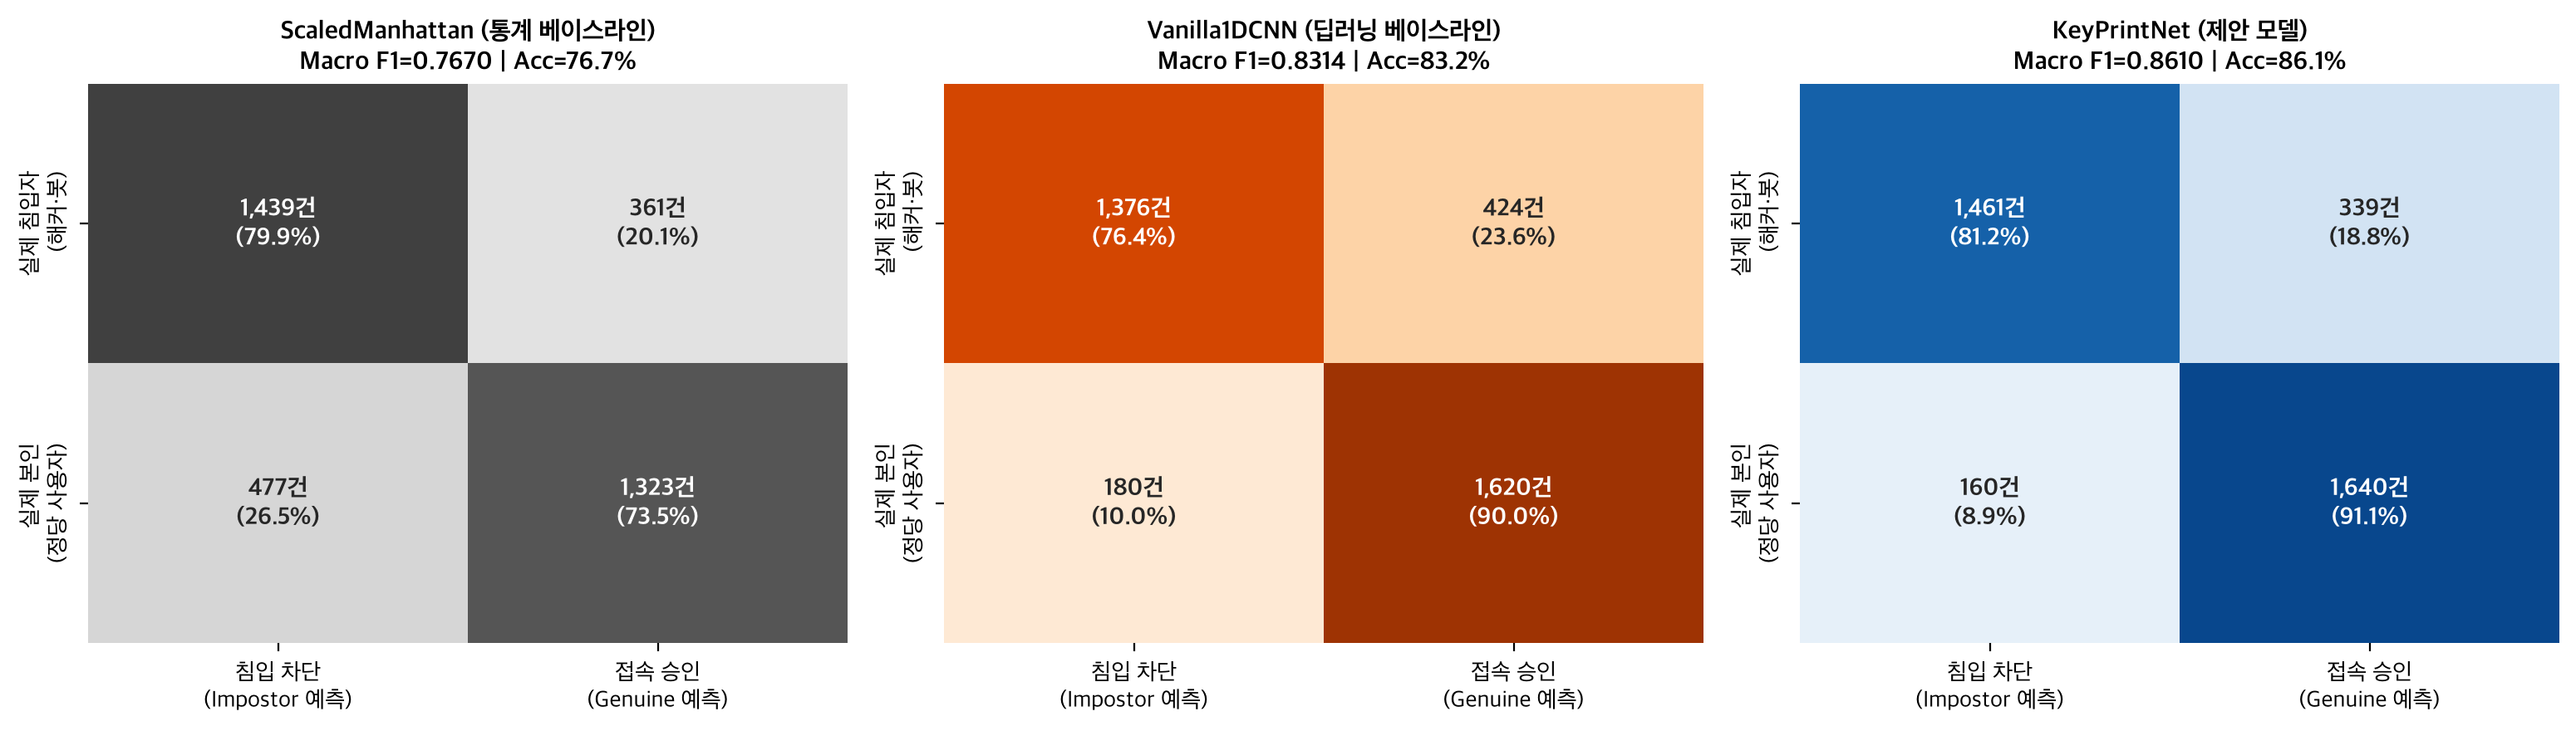

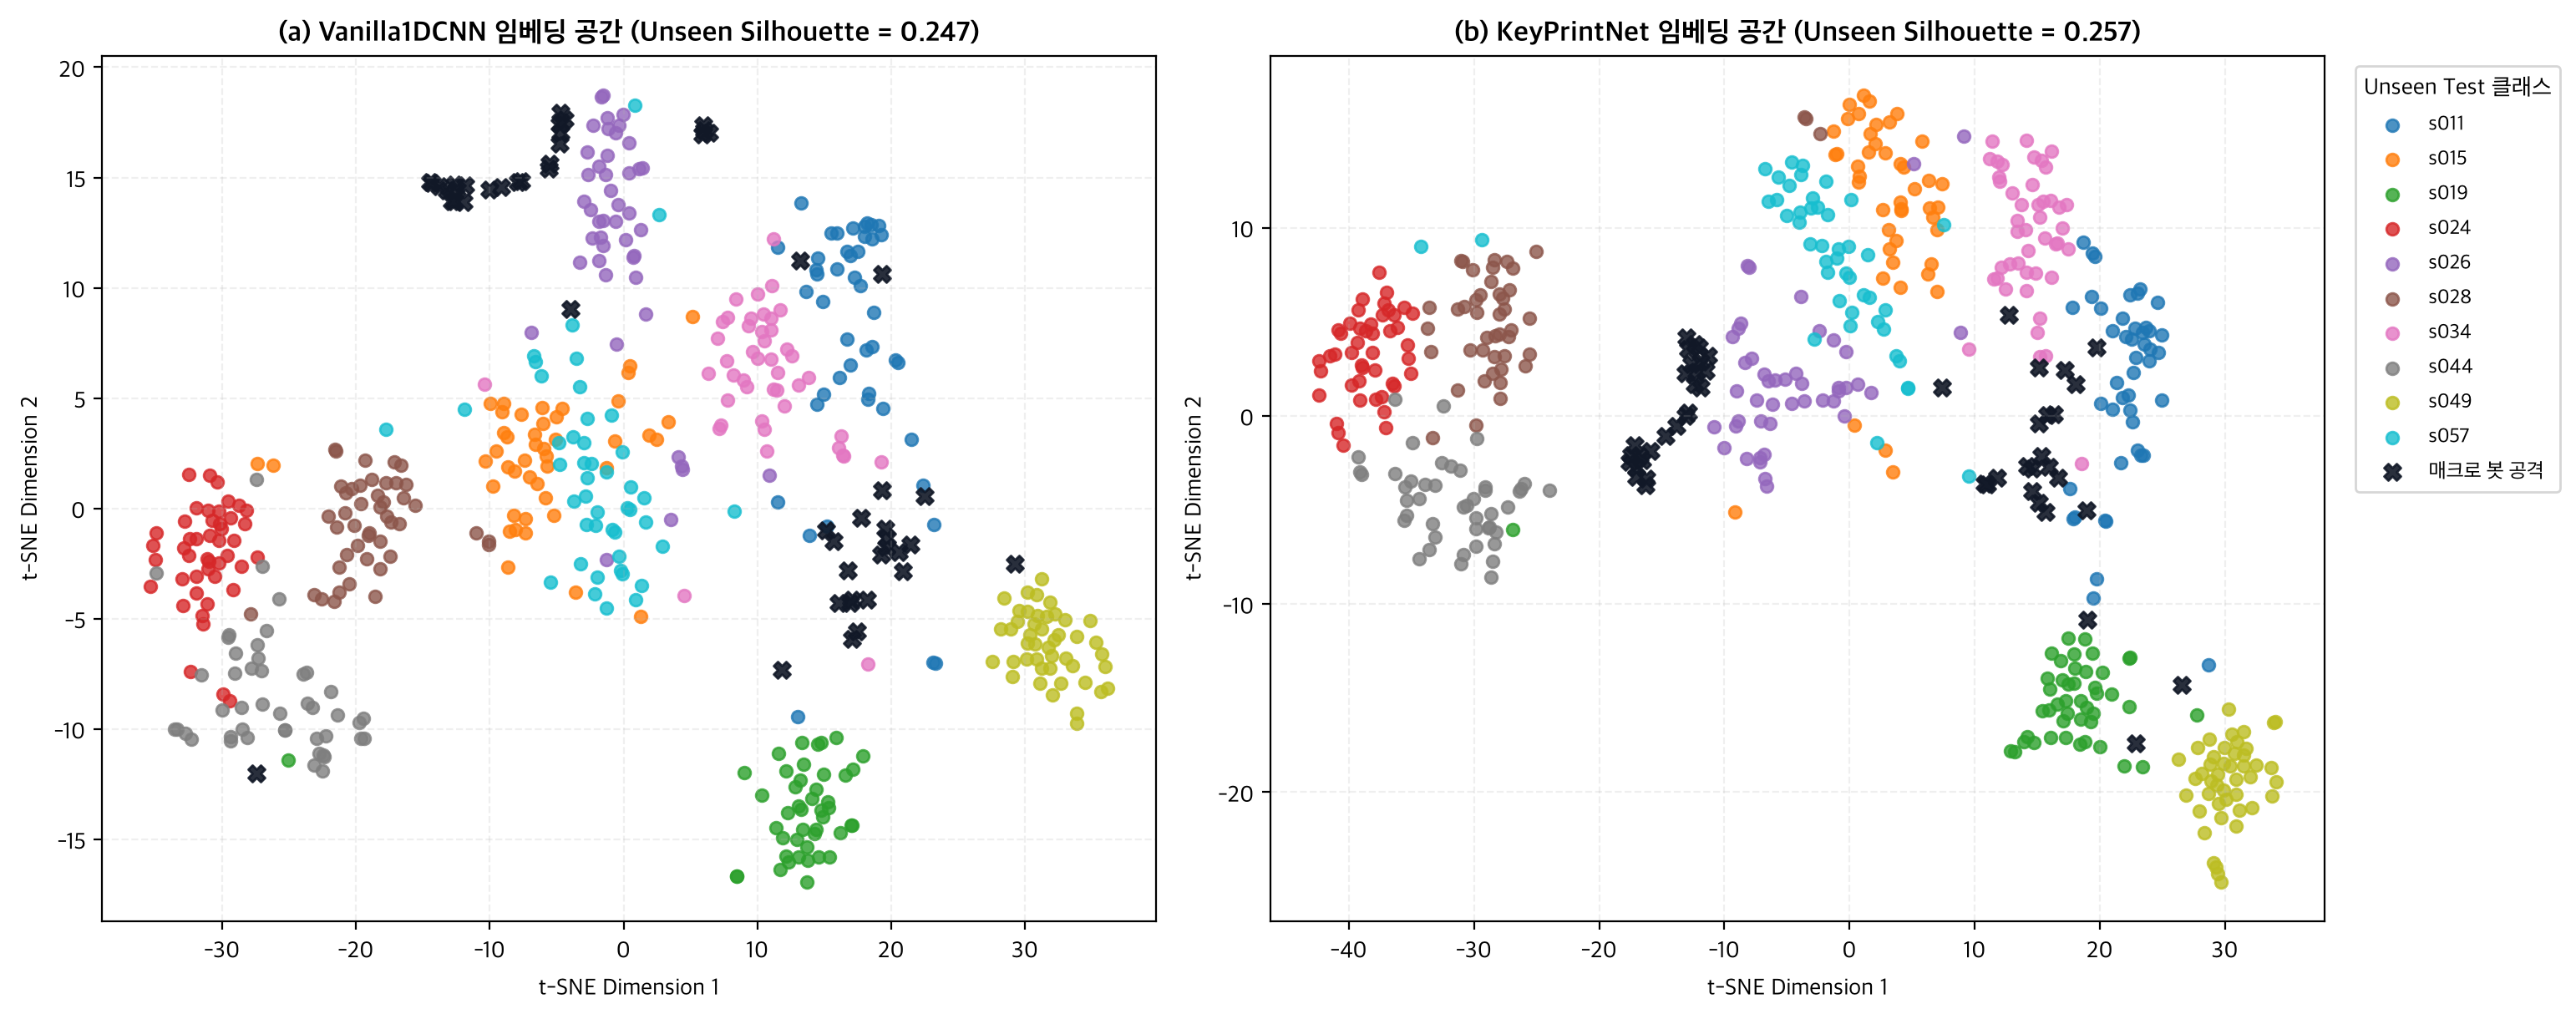

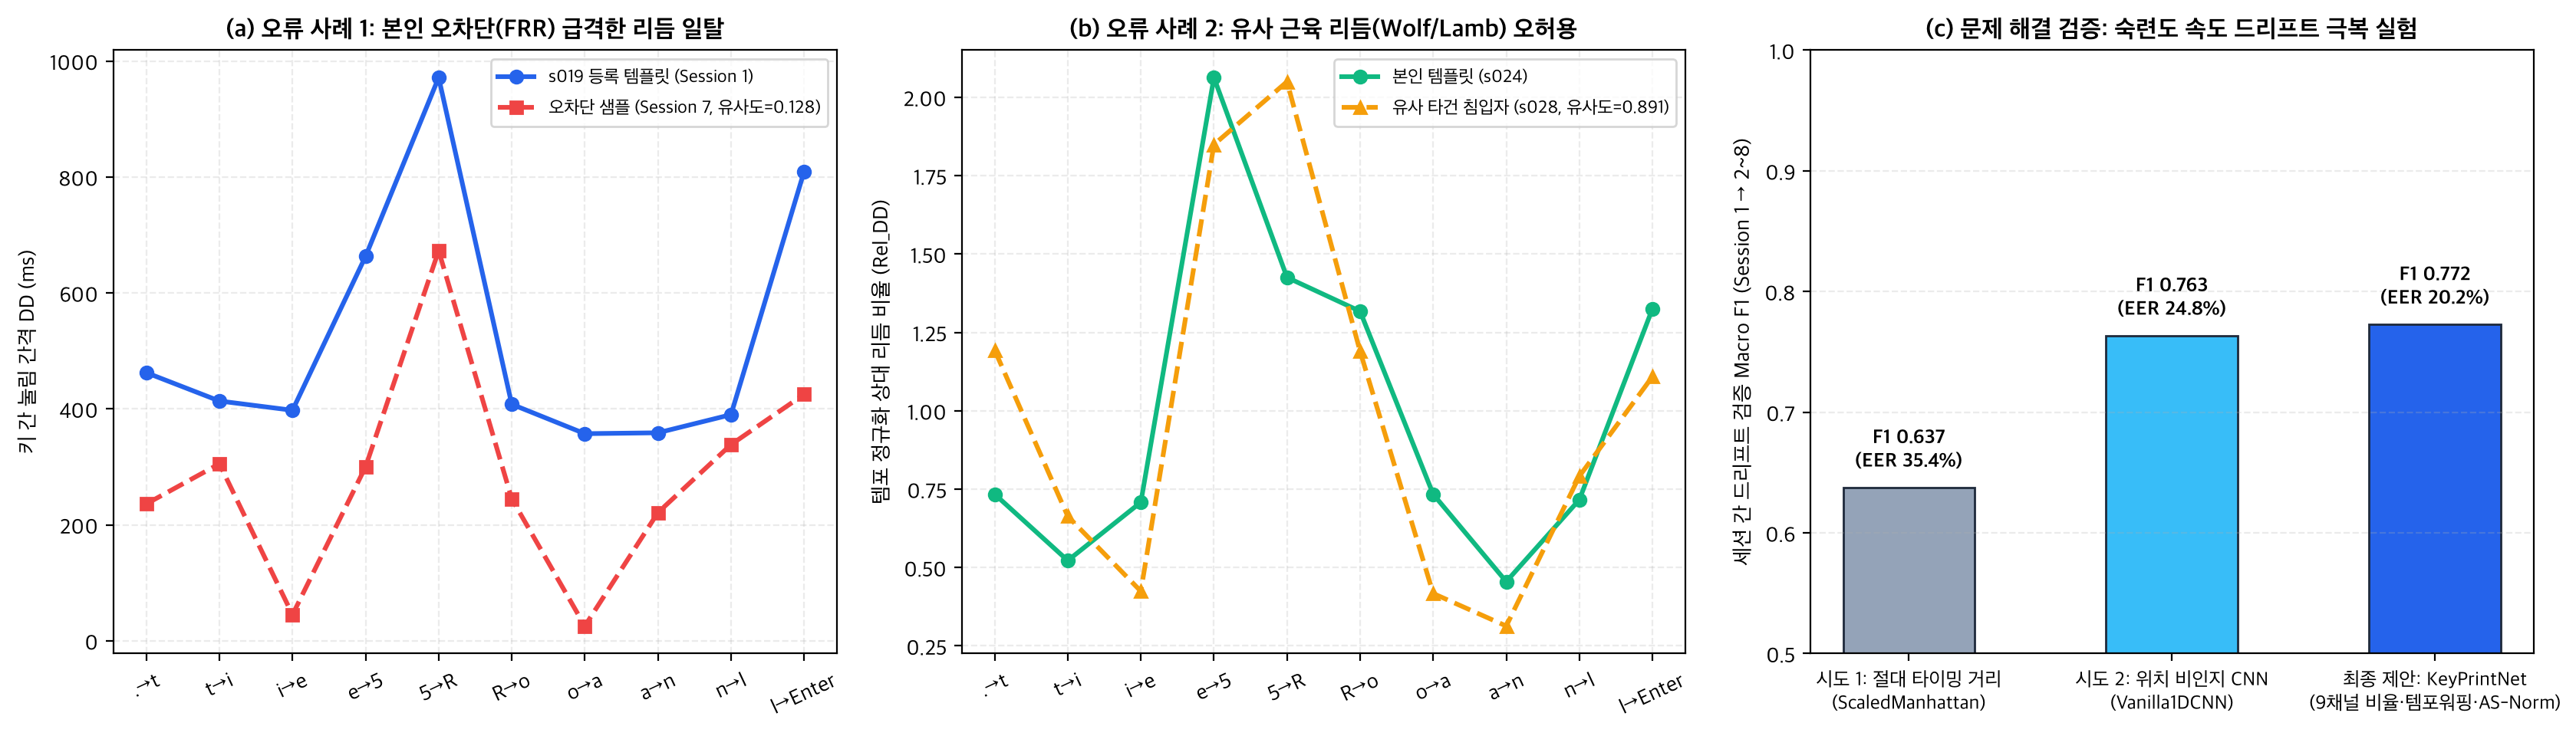

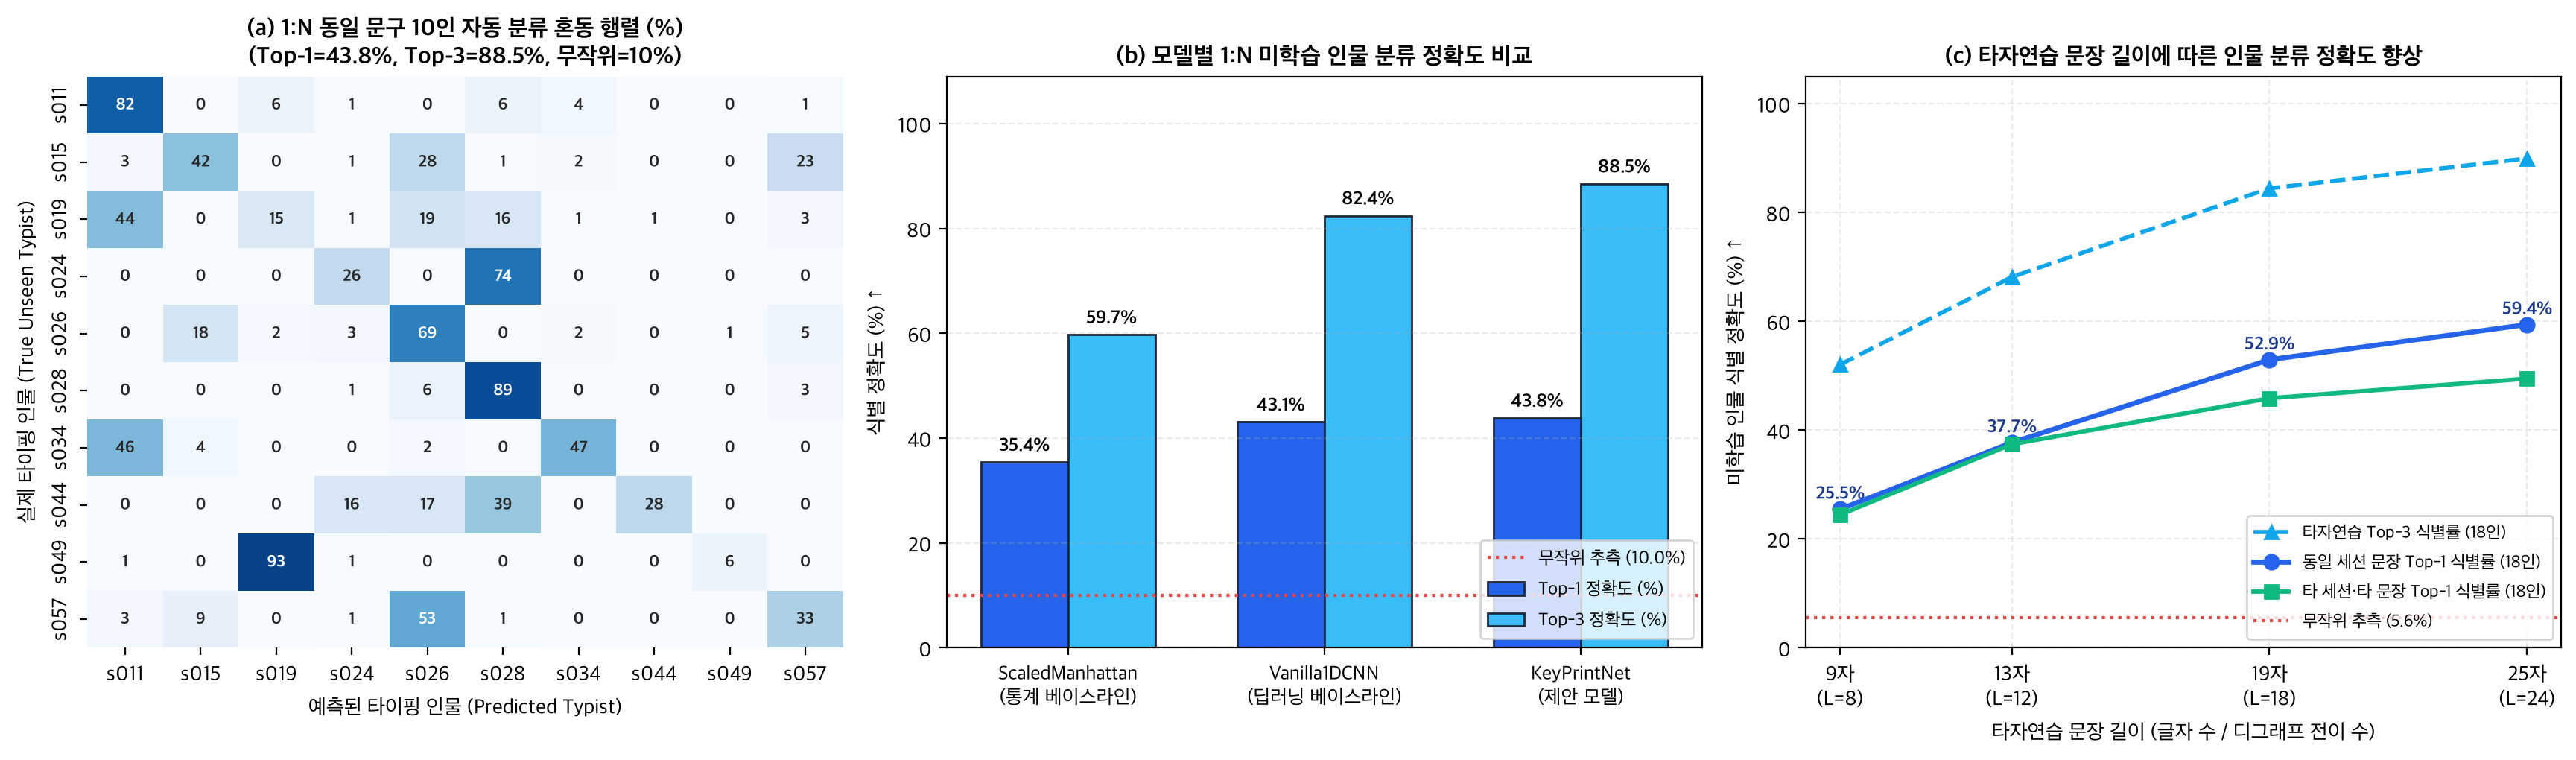

In [7]:
for fig_name in [
    'fig2_learning_curves.png',
    'fig3_roc_det_kshot.png',
    'fig4_confusion_matrices.png',
    'fig5_embedding_tsne.png',
    'fig6_error_analysis_and_ablation.png',
    'fig7_typist_identification.png',
]:
    ipy_display(Image(filename=str(ROOT / 'assets/figures' / fig_name), width=960))

## 5. 웹 배포용 ONNX 모델 가변 길이(암호 6자 ~ 타자연습 33자) 추론 및 정밀도 일치 검증

In [8]:
onnx_file = ROOT / 'models/keyprint_net.onnx'
sess = ort.InferenceSession(str(onnx_file), providers=['CPUExecutionProvider'])
cpu_net = KeyPrintNet(in_channels=9, hidden_channels=80, embed_dim=64, dropout=0.0)
cpu_net.load_state_dict(torch.load(ROOT / 'models/keyprint_net.pt', map_location='cpu'))
cpu_net.eval()

print(f'ONNX 가중치 파일 크기: {onnx_file.stat().st_size / 1024:.2f} KB (GitHub Pages 정적 호스팅 최적화)')
for seq_len in [5, 10, 18, 24, 32]:
    sample_in = np.random.RandomState(seq_len).randn(1, 9, seq_len).astype(np.float32)
    with torch.no_grad():
        pt_emb = cpu_net(torch.from_numpy(sample_in)).numpy()
    t0 = time.perf_counter()
    ort_emb = sess.run(['biometric_embedding'], {'keystroke_seq': sample_in})[0]
    dt_ms = (time.perf_counter() - t0) * 1000
    max_err = np.max(np.abs(pt_emb - ort_emb))
    print(f'  타건 전이 길이 L={seq_len:2d} ({seq_len+1:2d}자 문장) -> 출력 차원 {ort_emb.shape} | PyTorch-ONNX 최대 오차: {max_err:.2e} | 추론 시간: {dt_ms:.3f} ms')

ONNX 가중치 파일 크기: 591.87 KB (GitHub Pages 정적 호스팅 최적화)
  타건 전이 길이 L= 5 ( 6자 문장) -> 출력 차원 (1, 64) | PyTorch-ONNX 최대 오차: 2.38e-07 | 추론 시간: 0.424 ms
  타건 전이 길이 L=10 (11자 문장) -> 출력 차원 (1, 64) | PyTorch-ONNX 최대 오차: 3.50e-07 | 추론 시간: 0.154 ms
  타건 전이 길이 L=18 (19자 문장) -> 출력 차원 (1, 64) | PyTorch-ONNX 최대 오차: 2.46e-07 | 추론 시간: 0.269 ms
  타건 전이 길이 L=24 (25자 문장) -> 출력 차원 (1, 64) | PyTorch-ONNX 최대 오차: 3.50e-07 | 추론 시간: 0.293 ms
  타건 전이 길이 L=32 (33자 문장) -> 출력 차원 (1, 64) | PyTorch-ONNX 최대 오차: 2.38e-07 | 추론 시간: 0.248 ms
